In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("/Users/emilychoong/MATH30009 Online Temperature Forecasting /outputs/results.csv")

In [3]:
df.head()

,algorithm,params,p,k,mse,mae,n
0,AROWR,r=0.1,3.0,1,30.259467,4.415445,21044
1,AROWR,r=0.1,3.0,2,30.271368,4.416342,21044
2,AROWR,r=0.1,3.0,3,30.281710,4.417121,21044
3,AROWR,r=0.1,3.0,4,30.290348,4.417771,21044
4,AROWR,r=0.1,3.0,5,30.297231,4.418284,21044


In [10]:
df['k'].nunique()

9


=== k = 4 ===
      algorithm    params       mae        mse
21        AROWR  r=0.0001  4.379091  29.393151
39  persistence            1.731006   5.365077
48    yesterday            1.928022   6.495810


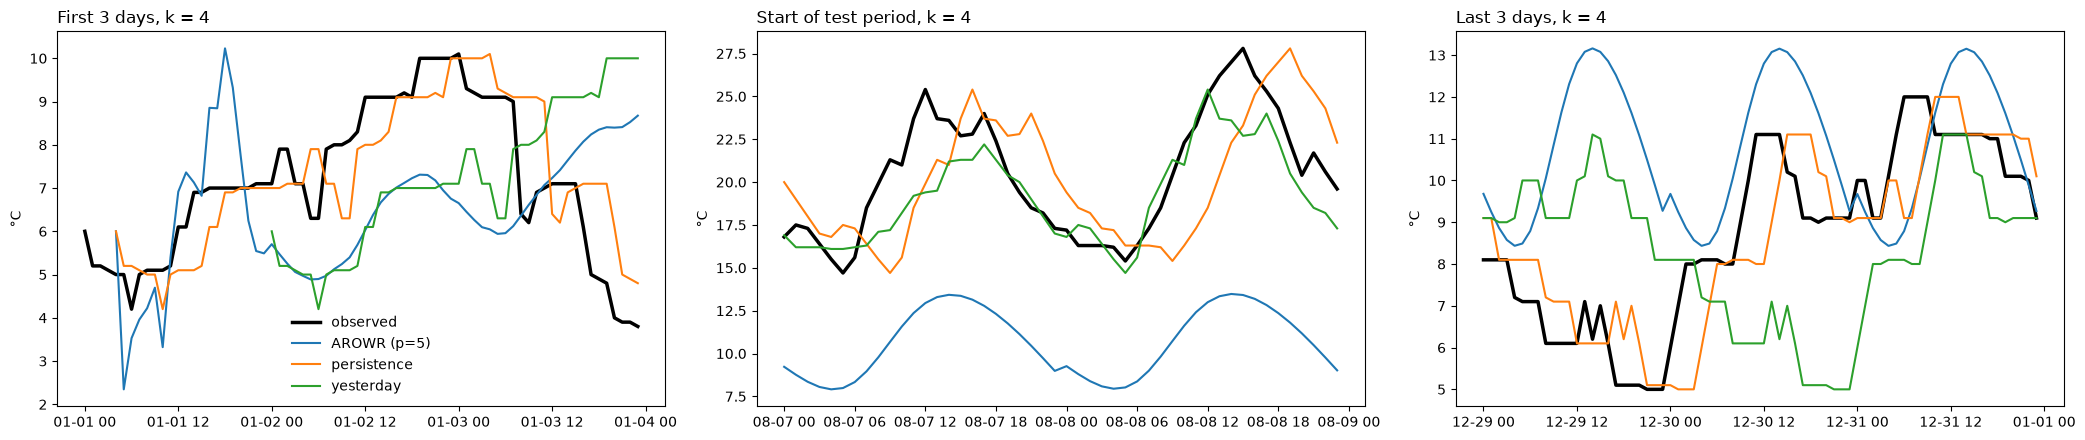


=== k = 5 ===
      algorithm    params       mae        mse
22        AROWR  r=0.0001  4.379451  29.398093
40  persistence            2.057413   7.437538
49    yesterday            1.928022   6.495810


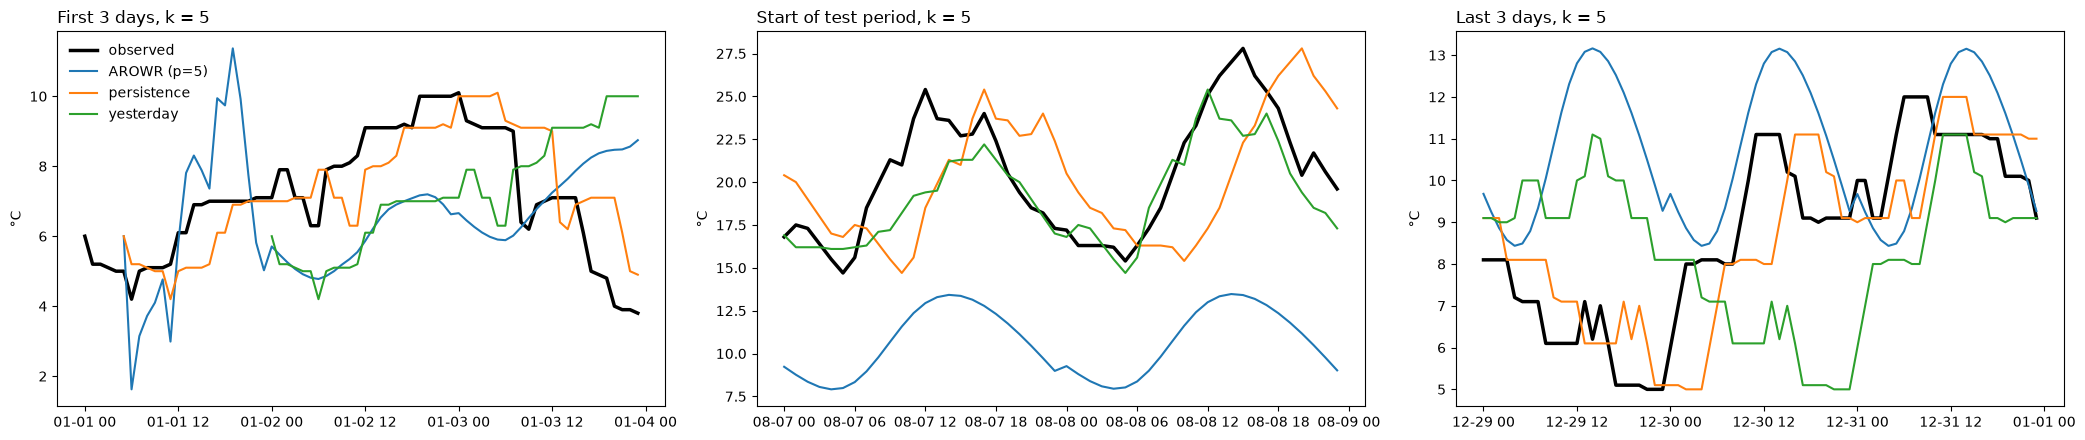


=== k = 6 ===
      algorithm    params       mae        mse
23        AROWR  r=0.0001  4.379535  29.399348
41  persistence            2.345590   9.528483
50    yesterday            1.928022   6.495810


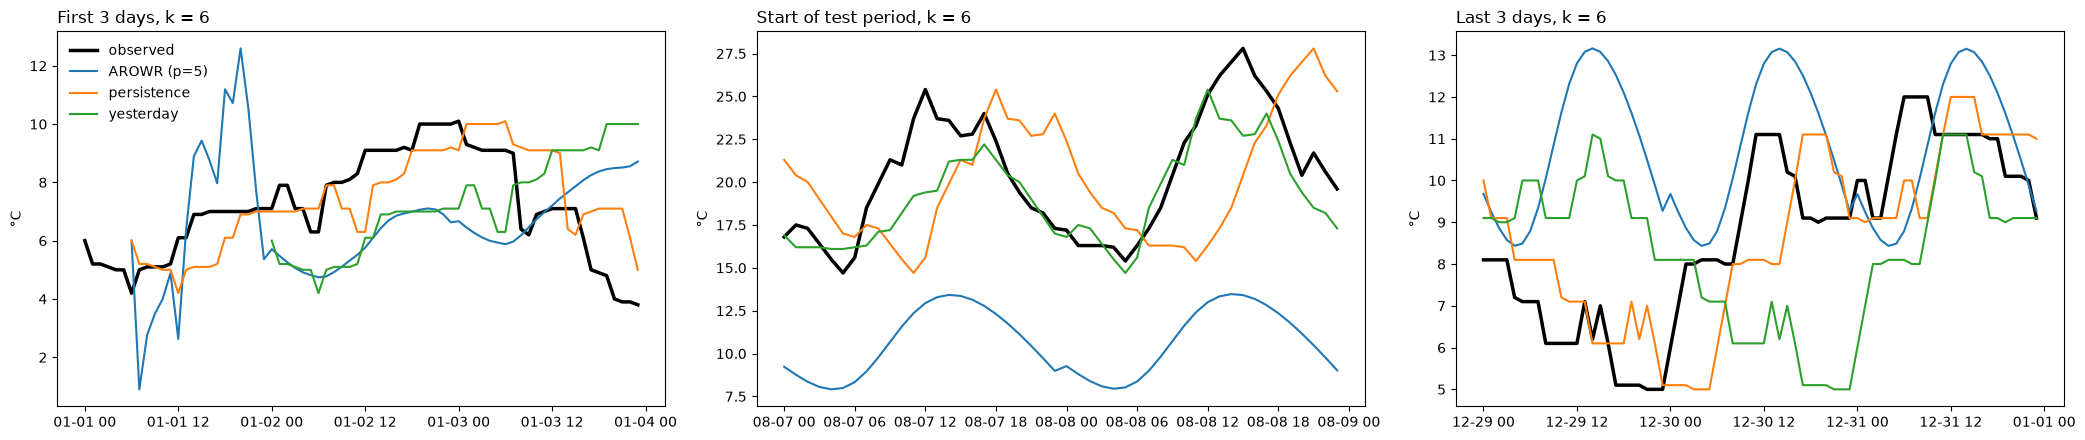


=== k = 7 ===
      algorithm    params       mae        mse
24        AROWR  r=0.0001  4.379441  29.398154
42  persistence            2.599810  11.519078
51    yesterday            1.928022   6.495810


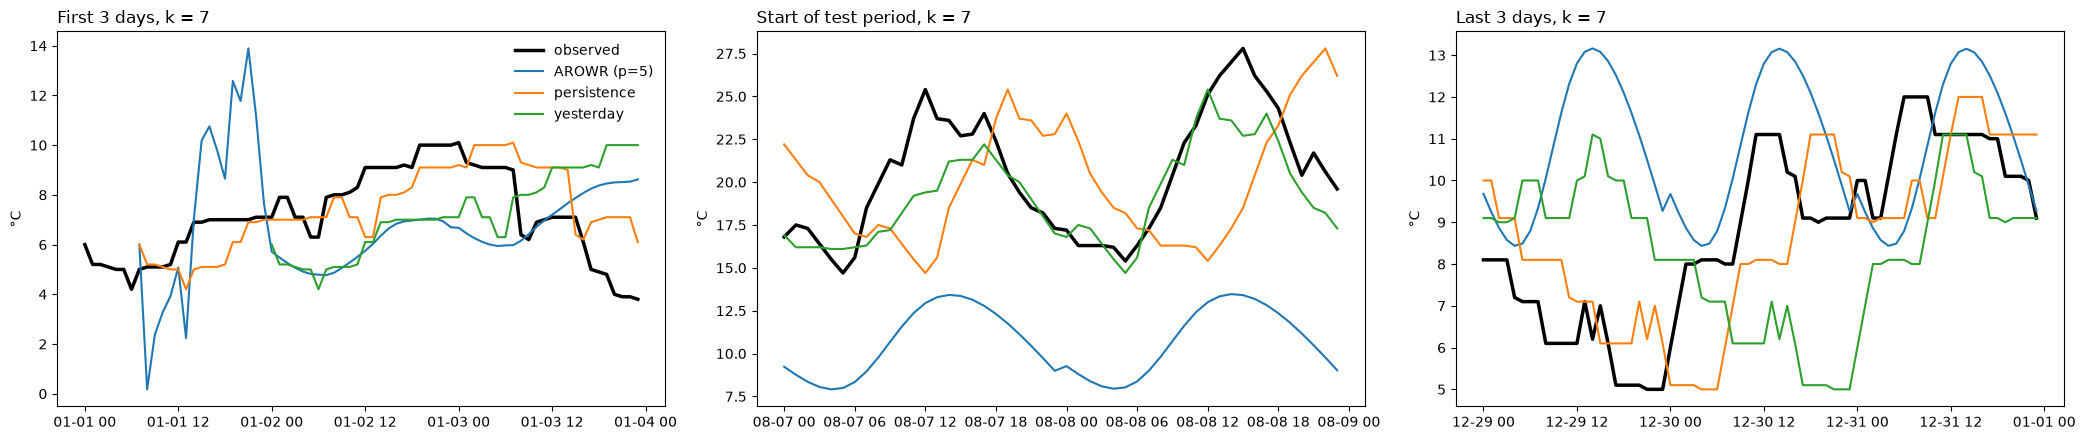


=== k = 8 ===
      algorithm    params       mae        mse
25        AROWR  r=0.0001  4.379271  29.395868
43  persistence            2.809594  13.325026
52    yesterday            1.928022   6.495810


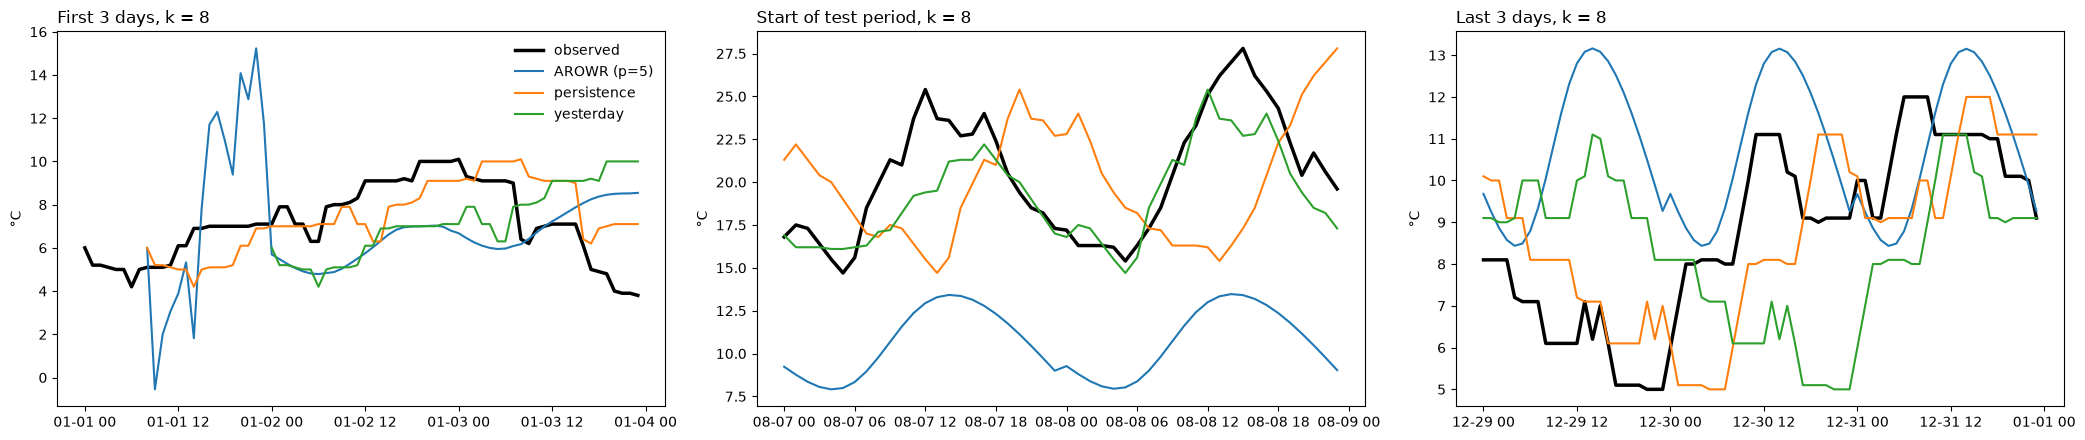


=== k = 9 ===
      algorithm    params       mae        mse
26        AROWR  r=0.0001  4.379111  29.393649
44  persistence            2.981924  14.866130
53    yesterday            1.928022   6.495810


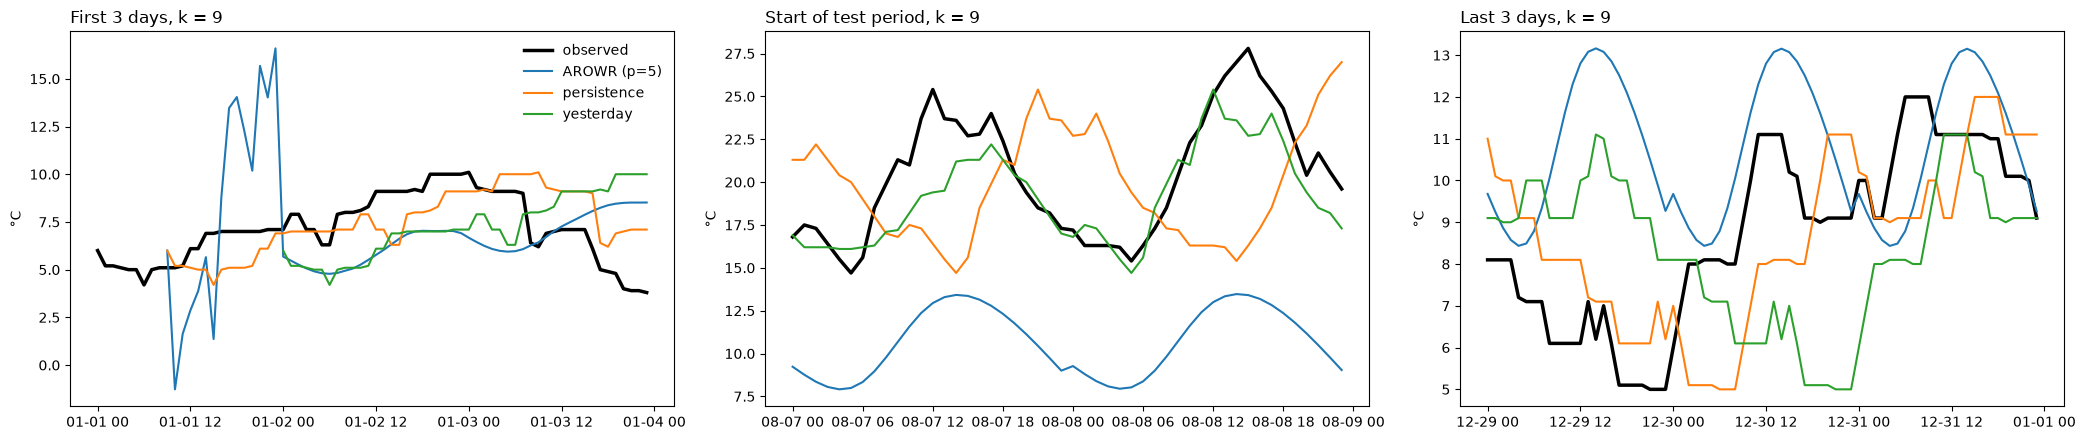

In [11]:
import matplotlib.pyplot as plt
from outputs_io import load_results, load_predictions

res, pred = load_results(), load_predictions()
p = 5

windows = {"First 3 days": ("2020-01-01", "2020-01-04"),
           "Start of test period": ("2020-08-07", "2020-08-09"),
           "Last 3 days":  ("2022-12-29", "2023-01-01")}

for k in [4, 5, 6, 7, 8, 9]:
    print(f"\n=== k = {k} ===")
    print(res[(res.k == k) & ((res.p == p) | res.p.isna())][["algorithm", "params", "mae", "mse"]])

    cols = {"obs": "observed", f"AROWR_k{k}_p{p}": f"AROWR (p={p})",
            f"persistence_k{k}": "persistence", f"yesterday_k{k}": "yesterday"}

    fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
    for ax, (title, (a, b)) in zip(axes, windows.items()):
        w = pred[(pred.time >= a) & (pred.time < b)]
        for c, lab in cols.items():
            ax.plot(w.time, w[c], label=lab, lw=2.5 if c == "obs" else 1.5,
                    color="black" if c == "obs" else None)
        ax.set_title(f"{title}, k = {k}", loc="left"); ax.set_ylabel("°C")
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(f"figures/k{k}_p{p}_first_last_days.png", dpi=150, bbox_inches="tight")
    plt.show()      # in a notebook, shows each chart as it's made
    plt.close(fig)  # stops 5 open figures piling up in memory

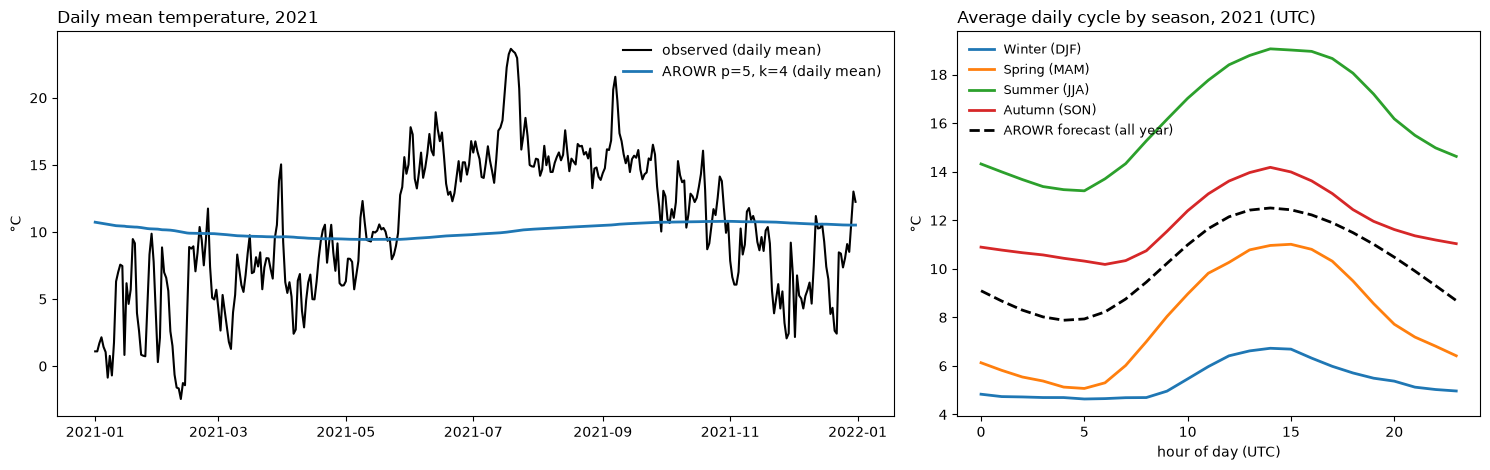

In [5]:
pred = load_predictions().set_index("time")
yr, col = pred.loc["2021"], "AROWR_k4_p5"
daily = yr[["obs", col]].resample("D").mean()
seasons = {"Winter (DJF)": [12, 1, 2], "Spring (MAM)": [3, 4, 5],
           "Summer (JJA)": [6, 7, 8], "Autumn (SON)": [9, 10, 11]}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(daily.index, daily.obs, color="black", lw=1.5, label="observed (daily mean)")
axes[0].plot(daily.index, daily[col], lw=2, label="AROWR p=5, k=4 (daily mean)")
axes[0].set_title("Daily mean temperature, 2021", loc="left"); axes[0].set_ylabel("°C")
axes[0].legend(frameon=False)

for s, months in seasons.items():
    sub = yr[yr.index.month.isin(months)]
    axes[1].plot(sub.groupby(sub.index.hour)["obs"].mean(), lw=2, label=s)
axes[1].plot(yr.groupby(yr.index.hour)[col].mean(), "k--", lw=2, label="AROWR forecast (all year)")
axes[1].set_title("Average daily cycle by season, 2021 (UTC)", loc="left")
axes[1].set_xlabel("hour of day (UTC)"); axes[1].set_ylabel("°C")
axes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("figures/seasonal_2021.png", dpi=150, bbox_inches="tight")